In [2]:
import pandas as pd

df = pd.read_excel("/content/student_essays_dataset.xlsx")
df.head()

,essay_id,essay_text,human_score
0,1,Artificial intelligence is increasingly being ...,15
1,2,Technology has changed how students learn and ...,14
2,3,The use of artificial intelligence in educatio...,16
3,4,Education is not only about grades but also ab...,17
4,5,Artificial intelligence can help teachers mana...,13


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   essay_id     10 non-null     int64 
 1   essay_text   10 non-null     object
 2   human_score  10 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 372.0+ bytes


In [4]:
!pip install nltk spacy textstat language-tool-python transformers torch scikit-learn shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.6/176.6 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.0/51.0 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 29.0 MB/s eta 0:00:00


In [7]:
import nltk


nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [8]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# download resources (run once)
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(w) for w in tokens if w not in stop_words]
    return " ".join(tokens)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [9]:
df["clean_text"] = df["essay_text"].apply(preprocess_text)
df[["essay_text", "clean_text"]].head()

,essay_text,clean_text
0,Artificial intelligence is increasingly being ...,artificial intelligence increasingly used educ...
1,Technology has changed how students learn and ...,technology changed student learn submit assign...
2,The use of artificial intelligence in educatio...,use artificial intelligence education offer ma...
3,Education is not only about grades but also ab...,education grade also learning improvement auto...
4,Artificial intelligence can help teachers mana...,artificial intelligence help teacher manage la...


In [10]:
import textstat

df["word_count"] = df["essay_text"].apply(lambda x: len(x.split()))
df["sentence_count"] = df["essay_text"].apply(textstat.sentence_count)
df["lexical_diversity"] = df["essay_text"].apply(
    lambda x: textstat.lexicon_count(x, removepunct=True) / max(len(x.split()), 1)
)
df["readability"] = df["essay_text"].apply(textstat.flesch_reading_ease)

df[["word_count", "sentence_count", "lexical_diversity", "readability"]].head()

,word_count,sentence_count,lexical_diversity,readability
0,52,4,1.0,22.813077
1,37,3,1.0,34.262613
2,42,3,1.0,25.439286
3,40,3,1.0,38.906667
4,36,3,1.0,20.755000


In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=300)
X = tfidf.fit_transform(df["clean_text"])
y = df["human_score"]

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [14]:
from sklearn.linear_model import LinearRegression

baseline_model = LinearRegression()
baseline_model.fit(X_train, y_train)

LinearRegression()

In [15]:
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

y_pred = baseline_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
corr, _ = pearsonr(y_test, y_pred)

mse, corr

(2.5136366769062883, np.float64(-1.0))

In [16]:
from sklearn.model_selection import cross_val_score

cv_mse = -cross_val_score(
    baseline_model,
    X,
    y,
    scoring="neg_mean_squared_error",
    cv=5
)

cv_mse.mean(), cv_mse

(np.float64(2.113191626362986),
 array([0.88674546, 2.04427901, 4.99254251, 0.21567197, 2.42671917]))

In [17]:
!pip install transformers torch scikit-learn

In [18]:
import torch
from transformers import BertTokenizer, BertModel
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from scipy.stats import pearsonr

In [19]:
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
bert_model = BertModel.from_pretrained("bert-base-uncased")
bert_model.eval()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSdpaSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False

In [20]:
def get_bert_embedding(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )
    with torch.no_grad():
        outputs = bert_model(**inputs)
    return outputs.last_hidden_state.mean(dim=1).squeeze().numpy()

In [21]:
X_bert = np.vstack(df["essay_text"].apply(get_bert_embedding))
y = df["human_score"].values

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X_bert, y, test_size=0.2, random_state=42
)

In [23]:
bert_regressor = LinearRegression()
bert_regressor.fit(X_train, y_train)

LinearRegression()

In [24]:
y_pred_bert = bert_regressor.predict(X_test)

mse_bert = mean_squared_error(y_test, y_pred_bert)
corr_bert, _ = pearsonr(y_test, y_pred_bert)

mse_bert, corr_bert

(1.6387693881988525, np.float64(1.0))

In [25]:
!pip install shap

In [26]:
import shap

explainer = shap.Explainer(
    bert_regressor,
    X_train
)

In [27]:
shap_values = explainer(X_test)

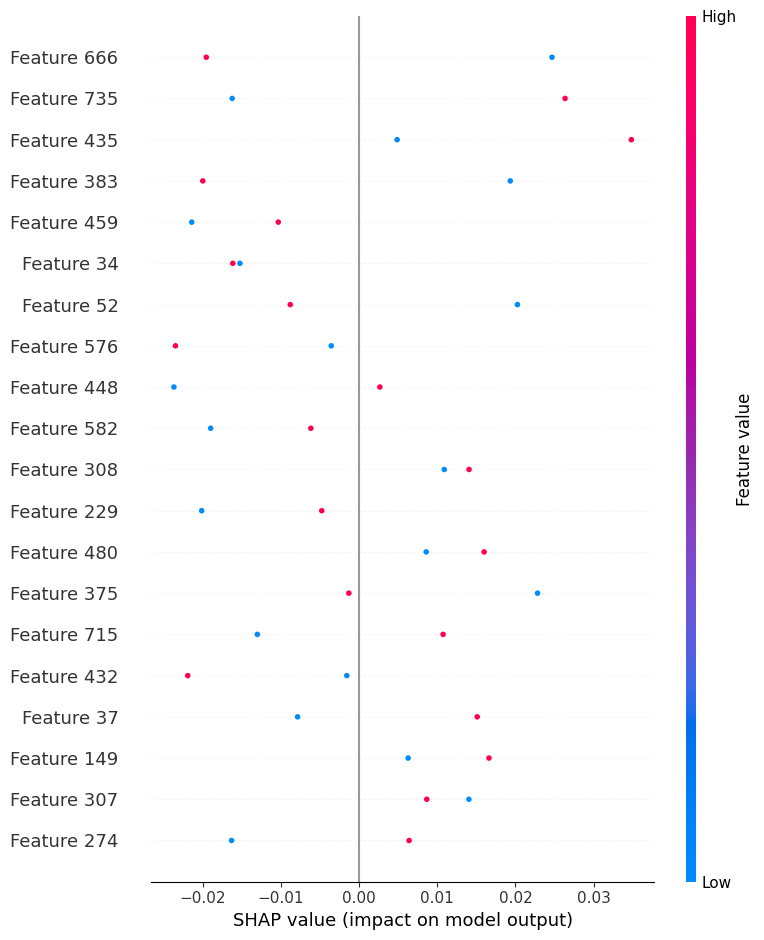

In [28]:
shap.summary_plot(shap_values, X_test)

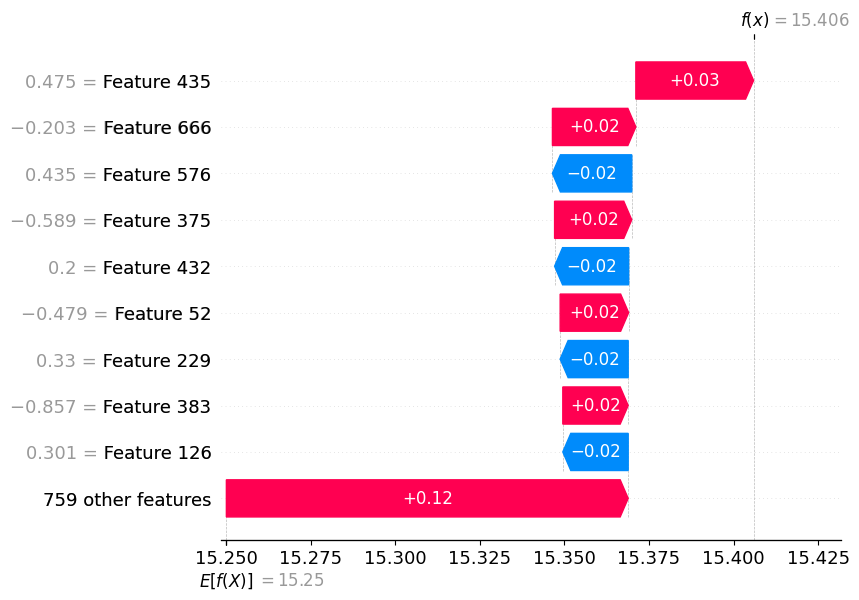

In [29]:
shap.plots.waterfall(shap_values[0])